# Ejercicios Prácticos
## Ejercicio 2

In [2]:
import statsmodels.api as sm
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.formula.api as smf

In [3]:
df = sm.datasets.get_rdataset("airquality", "datasets").data

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Ozone    116 non-null    float64
 1   Solar.R  146 non-null    float64
 2   Wind     153 non-null    float64
 3   Temp     153 non-null    int64  
 4   Month    153 non-null    int64  
 5   Day      153 non-null    int64  
dtypes: float64(3), int64(3)
memory usage: 7.3 KB


### Eliminación de filas donde hay valores faltantes en los campos **Ozone** y **Solar.R**

In [5]:
clean_df = df.dropna(subset=['Solar.R', 'Ozone'])

In [6]:
clean_df.rename(columns={'Solar.R': 'Solar_R'}, inplace=True)

C:\Users\aaron\AppData\Local\Temp\ipykernel_16664\3630212877.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  clean_df.rename(columns={'Solar.R': 'Solar_R'}, inplace=True)


In [7]:
clean_df

,Ozone,Solar_R,Wind,Temp,Month,Day
0,41.0,190.0,7.4,67,5,1
1,36.0,118.0,8.0,72,5,2
2,12.0,149.0,12.6,74,5,3
3,18.0,313.0,11.5,62,5,4
6,23.0,299.0,8.6,65,5,7
...,...,...,...,...,...,...
147,14.0,20.0,16.6,63,9,25
148,30.0,193.0,6.9,70,9,26
150,14.0,191.0,14.3,75,9,28
151,18.0,131.0,8.0,76,9,29


### Antes de hacer las estimaciones, hagamos graficaciones de la variables $x$ e $y$

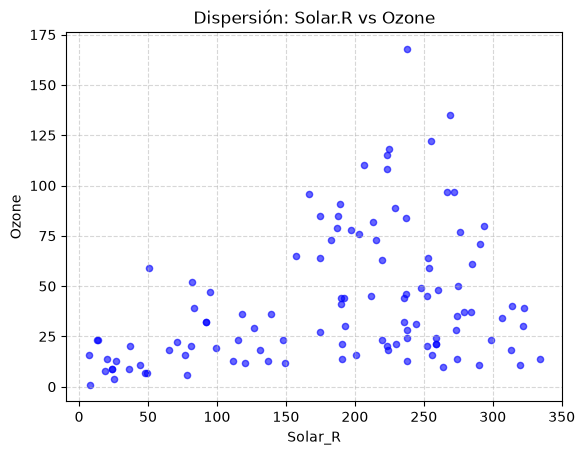

In [9]:
# Crear el gráfico de dispersión
# alpha=0.6 añade transparencia para visualizar la densidad de puntos superpuestos
clean_df.plot.scatter(x='Solar_R', y='Ozone', alpha=0.6, color='blue')

# Añadir detalles visuales
plt.title('Dispersión: Solar.R vs Ozone')
plt.xlabel('Solar_R')
plt.ylabel('Ozone')
plt.grid(True, linestyle='--', alpha=0.5)

# Renderizar
plt.show()

##Poner observaciones del scatterplot de arriba

## Estimaciones de $\beta_0$, $\beta_1$ y $\sigma^{2}$
Hay que recordar las ecuaciones estudiadas durante el tema de regresión Lineal, que a continuación son:
- $\beta_0 = \bar{y} - \hat{\beta_{1}}\bar{x}$
- $\beta_{1} = \frac{S_{xy}}{S_{xx}} = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n} (x_i - \bar{x})^2}$
- $\hat{\sigma}^2 = \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{n - 2}$

In [11]:
# Media muestral de X e Y
x_barra = np.mean(clean_df["Solar_R"])
y_barra = np.mean(clean_df["Ozone"])

# Cálculo de Sxy y Sxx
sxy = sum((clean_df["Solar_R"] - x_barra)*(clean_df["Ozone"] - y_barra))
sxx = sum((clean_df["Solar_R"] - x_barra)**2)

# Estimadores
beta_1 = sxy/sxx
beta_0 = y_barra - beta_1*x_barra

print(f"Promedio de X: {x_barra}")
print(f"Promedio de Y: {y_barra}")
print("=========================")
print("Cálculos de Sxy e Sxx")
print(f"Sxy: {sxy}")
print(f"Sxx: {sxx}")
print("=========================")
print("Estimadores de beta 0 y beta 1")
print(f"beta 0: {beta_0}")
print(f"beta 1: {beta_1}")

Promedio de X: 184.80180180180182
Promedio de Y: 42.0990990990991
Cálculos de Sxy e Sxx
Sxy: 116224.18018018018
Sxx: 913961.6396396396
Estimadores de beta 0 y beta 1
beta 0: 18.598727772023313
beta 1: 0.12716527164751193


In [22]:
model_df = clean_df[["Ozone", "Solar_R"]]

In [23]:
## Obtención de la varianza
## para obtener nuestro estimador de la variannza necesitamos calcular y_i estimada para cada x_i
model_df["Ozone_estimanda"] = beta_0 + beta_1 * clean_df['Solar_R']

In [24]:
model_df

,Ozone,Solar_R,Ozone_estimanda
0,41.0,190.0,42.760129
1,36.0,118.0,33.604230
2,12.0,149.0,37.546353
3,18.0,313.0,58.401458
6,23.0,299.0,56.621144
...,...,...,...
147,14.0,20.0,21.142033
148,30.0,193.0,43.141625
150,14.0,191.0,42.887295
151,18.0,131.0,35.257378


In [25]:
model_df["ei"] = model_df["Ozone"] - model_df["Ozone_estimanda"]

In [26]:
model_df["ei"].sum()

np.float64(1.3500311979441904e-13)

In [27]:
model_df

,Ozone,Solar_R,Ozone_estimanda,ei
0,41.0,190.0,42.760129,-1.760129
1,36.0,118.0,33.604230,2.395770
2,12.0,149.0,37.546353,-25.546353
3,18.0,313.0,58.401458,-40.401458
6,23.0,299.0,56.621144,-33.621144
...,...,...,...,...
147,14.0,20.0,21.142033,-7.142033
148,30.0,193.0,43.141625,-13.141625
150,14.0,191.0,42.887295,-28.887295
151,18.0,131.0,35.257378,-17.257378


In [30]:
n = model_df.shape[0]
sigma2 = (model_df["ei"].sum())*(model_df["ei"].sum())/(n - 2)
print(f"Estimador para la varianza:{sigma2}")

Estimador para la varianza:1.672095628828097e-28


Por lo tanto las estimaciones para mi modelos son $$\beta_0 = 18.598727772023313 $$ $$\beta_1 = 0.12716527164751193 $$ $$\sigma^2 = 1.672095628828097e-28 $$

## Valores ajustados de $\hat{y_i}$

In [34]:
model_df

,Ozone,Solar_R,Ozone_estimanda,ei
0,41.0,190.0,42.760129,-1.760129
1,36.0,118.0,33.604230,2.395770
2,12.0,149.0,37.546353,-25.546353
3,18.0,313.0,58.401458,-40.401458
6,23.0,299.0,56.621144,-33.621144
...,...,...,...,...
147,14.0,20.0,21.142033,-7.142033
148,30.0,193.0,43.141625,-13.141625
150,14.0,191.0,42.887295,-28.887295
151,18.0,131.0,35.257378,-17.257378


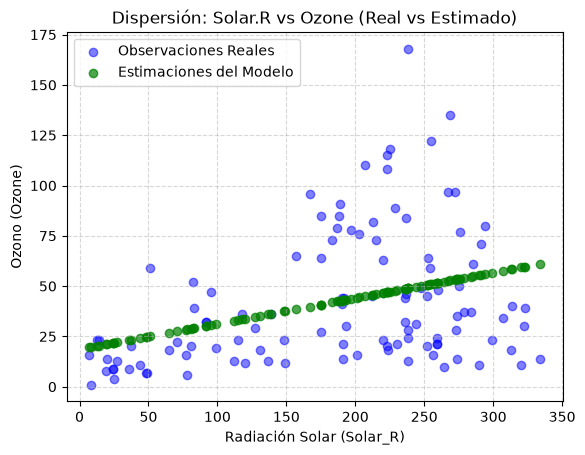

In [37]:
# 1. Graficar las observaciones reales (Datos empíricos)
plt.scatter(model_df['Solar_R'], model_df['Ozone'], 
            color='blue', alpha=0.5, label='Observaciones Reales')

# 2. Graficar las estimaciones (Predicciones del modelo)
plt.scatter(model_df['Solar_R'], model_df['Ozone_estimanda'], 
            color='green', alpha=0.7, label='Estimaciones del Modelo')

# 3. Añadir detalles visuales
plt.title('Dispersión: Solar.R vs Ozone (Real vs Estimado)')
plt.xlabel('Radiación Solar (Solar_R)')
plt.ylabel('Ozono (Ozone)')
plt.grid(True, linestyle='--', alpha=0.5)

# 4. Activar la leyenda para identificar los colores
plt.legend(loc='best')

# 5. Renderizar
plt.show()

## Muestra que la suma de residuales es 0. Es decir:
$$ \sum_{i=1}^{n} e_i = \sum_{i=1}^{n} (y_i - \hat{y}_i) = 0 $$

In [40]:
#tenemos el dataframe model_df
# En las columna 
model_df

,Ozone,Solar_R,Ozone_estimanda,ei
0,41.0,190.0,42.760129,-1.760129
1,36.0,118.0,33.604230,2.395770
2,12.0,149.0,37.546353,-25.546353
3,18.0,313.0,58.401458,-40.401458
6,23.0,299.0,56.621144,-33.621144
...,...,...,...,...
147,14.0,20.0,21.142033,-7.142033
148,30.0,193.0,43.141625,-13.141625
150,14.0,191.0,42.887295,-28.887295
151,18.0,131.0,35.257378,-17.257378


In [44]:
suma_ei = sum(model_df["ei"])
print(f"La suma de residuales es: {suma_ei}")
# Y este valor se aproxima mucho a 0

La suma de residuales es: 1.2789769243681803e-13
